# Mobile Payments Fraud Detection (PaySim)

**Business question:** Which mobile-money transactions are likely fraud, and how should a risk team set its alert threshold?

**Data:** [PaySim](https://www.kaggle.com/datasets/ealaxi/paysim1) is a **simulated** dataset generated from real mobile-money logs. It has 6.36M transactions, of which about 8,200 (0.13%) are fraud. Each `step` is one hour of simulated time (743 steps ≈ 31 days).

**Plan**
1. Explore fraud by transaction type
2. Remove leaky and useless columns
3. Engineer balance-error and time features
4. Split by **time** (train on earlier hours, test on later ones)
5. Baseline: logistic regression · 6. Main model: random forest
7. Evaluate with precision, recall and PR-AUC (not accuracy)
8. Turn scores into a review-budget decision
9. Explain the model

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             confusion_matrix, precision_recall_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.4f}".format)
RANDOM_STATE = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FULL = ROOT / "data" / "PS_20174392719_1491204439457_log.csv"   # Kaggle file
SAMPLE = ROOT / "data" / "paysim_sample.csv"                     # scripts/make_sample_data.py
DATA_PATH = FULL if FULL.exists() else SAMPLE
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

print("Using:", DATA_PATH.name)
if DATA_PATH == SAMPLE:
    print("WARNING: running on the synthetic smoke-test sample. Download the Kaggle file for real results.")

Using: PS_20174392719_1491204439457_log.csv


### Load efficiently
The CSV is about 470 MB. Setting `dtype`s cuts memory sharply: `type` becomes a category and `step` and the labels become small ints. Balances stay `float64` because the balance-error features subtract large numbers, and `float32` would add rounding noise. We skip the two ID columns on load (see step 2).

In [2]:
DTYPES = {"step": "int16", "type": "category", "amount": "float64",
          "oldbalanceOrg": "float64", "newbalanceOrig": "float64",
          "oldbalanceDest": "float64", "newbalanceDest": "float64",
          "isFraud": "int8", "isFlaggedFraud": "int8"}
df = pd.read_csv(DATA_PATH, usecols=list(DTYPES), dtype=DTYPES)
print(f"{len(df):,} rows | {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")
print(f"Fraud: {df.isFraud.sum():,} ({df.isFraud.mean():.3%})")
df.head()

6,362,620 rows | 286 MB in memory
Fraud: 8,213 (0.129%)


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400","170,136.0000","160,296.3600",0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800","21,249.0000","19,384.7200",0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,181.0000,0.0000,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,181.0000,0.0000,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400","41,554.0000","29,885.8600",0.0000,0.0000,0,0


## 1. Explore: where does fraud happen?

In [3]:
by_type = (df.groupby("type", observed=True)
             .agg(transactions=("isFraud", "size"), fraud_count=("isFraud", "sum"),
                  fraud_amount=("amount", lambda s: s[df.loc[s.index, "isFraud"] == 1].sum()))
             .assign(fraud_rate=lambda t: t.fraud_count / t.transactions)
             .sort_values("transactions", ascending=False))
by_type

,transactions,fraud_count,fraud_amount,fraud_rate
type,,,,
CASH_OUT,2237500,4116,"5,989,202,243.8300",0.0018
PAYMENT,2151495,0,0.0000,0.0000
CASH_IN,1399284,0,0.0000,0.0000
TRANSFER,532909,4097,"6,067,213,184.0100",0.0077
DEBIT,41432,0,0.0000,0.0000


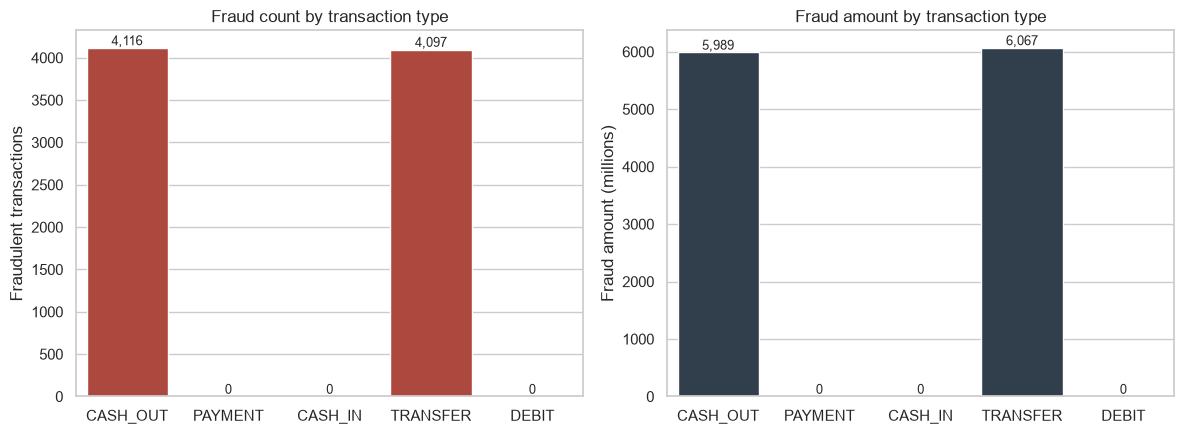

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
order = by_type.index.tolist()
sns.barplot(x=by_type.index, y=by_type.fraud_count, order=order, ax=axes[0], color="#c0392b")
axes[0].set(title="Fraud count by transaction type", xlabel="", ylabel="Fraudulent transactions")
sns.barplot(x=by_type.index, y=by_type.fraud_amount / 1e6, order=order, ax=axes[1], color="#2c3e50")
axes[1].set(title="Fraud amount by transaction type", xlabel="", ylabel="Fraud amount (millions)")
for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt="{:,.0f}", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "01_fraud_by_type.png", dpi=150); plt.show()

**Finding:** fraud appears **only in `TRANSFER` and `CASH_OUT`**. That matches the simulated fraud pattern: take over an account, transfer the balance to a mule account, then cash it out. `PAYMENT`, `CASH_IN` and `DEBIT` have zero fraud, so we **filter to TRANSFER and CASH_OUT**. That removes more than half the rows and loses no fraud.

In [5]:
df = df[df["type"].isin(["TRANSFER", "CASH_OUT"])].copy()
df["type"] = df["type"].cat.remove_unused_categories()
print(f"{len(df):,} rows after filter | fraud rate now {df.isFraud.mean():.3%}")

2,770,409 rows after filter | fraud rate now 0.296%


## 2. Check for leakage and useless columns

**`isFlaggedFraud`**: this is the simulator's **own built-in rule**: it flags transfers over 200,000. It is not an independent signal. It is an output of the same process that produced the labels, it fires on only a handful of rows, and a real bank would not have this exact rule. Leaving it in risks a model that copies the simulator's logic rather than learning behaviour. **Drop it.**

**`nameOrig` / `nameDest`**: these are account IDs. Almost every value is unique, so they contain no general pattern. A model could only *memorise* specific IDs, which does not carry over to new customers and can leak identity across the split. (We already skipped them on load. The cell below checks their cardinality on a small read.)

In [6]:
print(pd.crosstab(df.isFlaggedFraud, df.isFraud, margins=True))
names = pd.read_csv(DATA_PATH, usecols=["nameOrig", "nameDest"], nrows=500_000)
print("\nUnique share in first 500k rows:", (names.nunique() / len(names)).round(3).to_dict())
df = df.drop(columns="isFlaggedFraud")

isFraud               0     1      All
isFlaggedFraud                        
0               2762196  8197  2770393
1                     0    16       16
All             2762196  8213  2770409



Unique share in first 500k rows: {'nameOrig': 1.0, 'nameDest': 0.43}


## 3. Engineer features

In a clean ledger the origin and destination balances should reconcile with the amount. The **gap** between them is very informative:

- `errorOrig = oldbalanceOrg − amount − newbalanceOrig` (from the brief): 0 if the sender's books balance
- `errorDest = oldbalanceDest + amount − newbalanceDest`: 0 if the receiver's books balance
- `hour = step % 24`: fraud in PaySim is spread evenly over the day, while legitimate activity has a strong daily cycle
- Zero-balance flags: fraud often *empties* the origin account, and mule destinations often show zero balances

In [7]:
df["errorOrig"] = df.oldbalanceOrg - df.amount - df.newbalanceOrig
df["errorDest"] = df.oldbalanceDest + df.amount - df.newbalanceDest
df["hour"] = (df.step % 24).astype("int8")
df["origEmptied"] = ((df.oldbalanceOrg > 0) & (df.newbalanceOrig == 0)).astype("int8")
df["destZeroBoth"] = ((df.oldbalanceDest == 0) & (df.newbalanceDest == 0)).astype("int8")
df["isTransfer"] = (df["type"] == "TRANSFER").astype("int8")

FEATURES = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
            "errorOrig", "errorDest", "hour", "origEmptied", "destZeroBoth", "isTransfer"]
df.groupby("isFraud")[FEATURES].median().T

isFraud,0,1
amount,"171,034.4600","441,423.4400"
oldbalanceOrg,283.0000,"438,983.4500"
newbalanceOrig,0.0000,0.0000
oldbalanceDest,"558,272.9900",0.0000
newbalanceDest,"829,902.9300","4,676.4200"
errorOrig,"-144,200.8250",0.0000
errorDest,0.0000,"2,231.4600"
hour,16.0000,12.0000
origEmptied,0.0000,1.0000
destZeroBoth,0.0000,0.0000


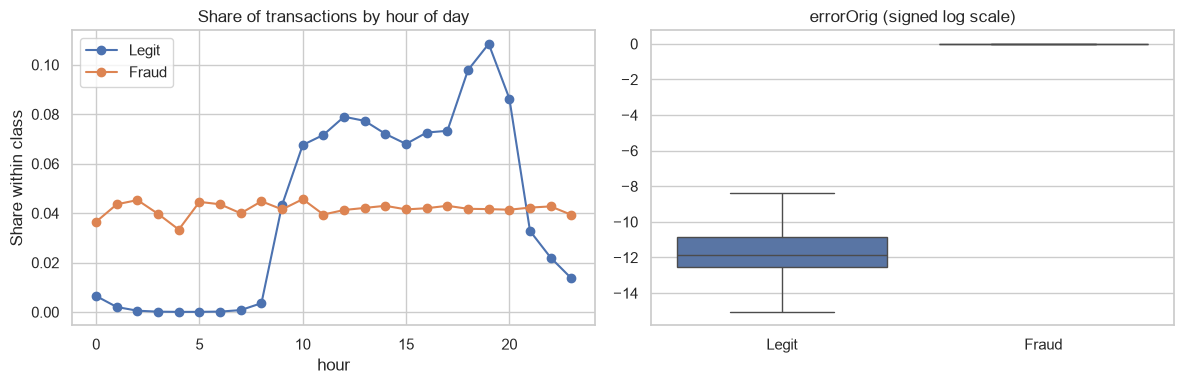

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
(df.groupby(["hour", "isFraud"]).size().unstack()
   .pipe(lambda t: t / t.sum()).plot(ax=axes[0], marker="o"))
axes[0].set(title="Share of transactions by hour of day", ylabel="Share within class")
axes[0].legend(["Legit", "Fraud"])
sns.boxplot(data=df.sample(min(len(df), 200_000), random_state=RANDOM_STATE), x="isFraud",
            y=np.sign(df.errorOrig) * np.log1p(df.errorOrig.abs()), ax=axes[1], showfliers=False)
axes[1].set_xticks([0, 1], ["Legit", "Fraud"])
axes[1].set(title="errorOrig (signed log scale)", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "02_feature_separation.png", dpi=150); plt.show()

## 4. Split by time, not randomly

A bank trains on the past and scores the future. A random split lets the model see "future" transactions during training. That inflates scores and hides drift. We put a cutoff at the step where 80% of rows have passed: everything before it is **train** and everything after is **test**.

In [9]:
cutoff = int(df.step.quantile(0.80))
train, test = df[df.step <= cutoff], df[df.step > cutoff]
X_train, y_train = train[FEATURES], train.isFraud
X_test, y_test = test[FEATURES], test.isFraud

print(f"Cutoff step: {cutoff} (hour {cutoff} of {df.step.max()})")
for name, part in [("train", train), ("test", test)]:
    print(f"{name:5}: steps {part.step.min()}-{part.step.max()} | {len(part):>9,} rows | "
          f"{part.isFraud.sum():>5,} fraud ({part.isFraud.mean():.3%})")

Cutoff step: 354 (hour 354 of 743)
train: steps 1-354 | 2,217,905 rows | 3,955 fraud (0.178%)
test : steps 355-743 |   552,504 rows | 4,258 fraud (0.771%)


Fraud in PaySim is spread evenly over time but legitimate volume falls off later, so the **test set has a higher fraud rate** than train. That is a realistic kind of drift, and the evaluation has to handle it.

## 5. Baseline: logistic regression
Amounts and balances are heavily skewed, so we apply a signed `log1p` and standardise before the linear model. `class_weight='balanced'` up-weights the rare fraud class instead of resampling.

In [10]:
signed_log = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))
logreg = make_pipeline(signed_log, StandardScaler(),
                       LogisticRegression(class_weight="balanced", max_iter=2000))
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic regression AP: {average_precision_score(y_test, p_lr):.4f}")

Logistic regression AP: 0.9844


## 6. Main model: random forest
(About 2–3M training rows with 200 trees takes a few minutes with `n_jobs=-1`.)

In [11]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=5,
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]
print(f"Random forest AP: {average_precision_score(y_test, p_rf):.4f}")

Random forest AP: 1.0000


## 7. Evaluate correctly

**Accuracy is useless here.** A model that always says "not fraud" scores about 99.87% on the full data and catches nothing. We report **precision** (of the alerts, how many are fraud), **recall** (of the fraud, how much we catch), **F1**, and **average precision** (area under the precision-recall curve). Average precision does not reward the model for the huge pile of easy negatives.

In [12]:
print(f"'Always legit' accuracy on test: {1 - y_test.mean():.4%}  <- why accuracy is meaningless\n")
for name, p in [("Logistic regression", p_lr), ("Random forest", p_rf)]:
    print(f"=== {name} @ 0.5 threshold ===")
    print(classification_report(y_test, (p >= 0.5).astype(int), target_names=["legit", "fraud"], digits=3))

'Always legit' accuracy on test: 99.2293%  <- why accuracy is meaningless

=== Logistic regression @ 0.5 threshold ===
              precision    recall  f1-score   support

       legit      1.000     0.999     1.000    548246
       fraud      0.924     0.995     0.958      4258

    accuracy                          0.999    552504
   macro avg      0.962     0.997     0.979    552504
weighted avg      0.999     0.999     0.999    552504

=== Random forest @ 0.5 threshold ===
              precision    recall  f1-score   support

       legit      1.000     1.000     1.000    548246
       fraud      0.999     1.000     0.999      4258

    accuracy                          1.000    552504
   macro avg      1.000     1.000     1.000    552504
weighted avg      1.000     1.000     1.000    552504



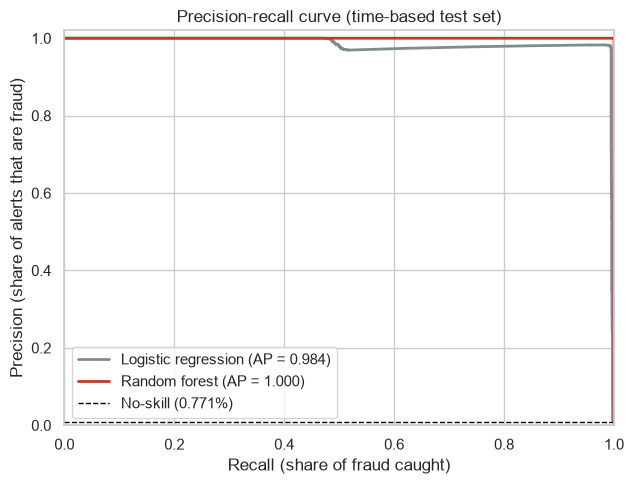

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for name, p, c in [("Logistic regression", p_lr, "#7f8c8d"), ("Random forest", p_rf, "#c0392b")]:
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax.plot(rec, prec, label=f"{name} (AP = {average_precision_score(y_test, p):.3f})", color=c, lw=2)
ax.axhline(y_test.mean(), ls="--", color="black", lw=1, label=f"No-skill ({y_test.mean():.3%})")
ax.set(xlabel="Recall (share of fraud caught)", ylabel="Precision (share of alerts that are fraud)",
       title="Precision-recall curve (time-based test set)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "03_precision_recall.png", dpi=150); plt.show()

## 8. Pick a threshold: the review-budget table

A risk team does not think in probabilities. It thinks in **analyst capacity**: "we can review X% of transactions." So we rank test transactions by fraud score and ask: **if we review the top 0.5%, 1%, 2% or 5%, what share of fraud (by count and by money) do we catch?**

In [14]:
def review_table(y, p, amount, budgets=(0.005, 0.01, 0.02, 0.05)):
    order = np.argsort(-p, kind="stable")
    y, p, amount = np.asarray(y)[order], np.asarray(p)[order], np.asarray(amount)[order]
    fraud_amt_total, fraud_total = (amount * y).sum(), y.sum()
    rows = []
    for b in budgets:
        k = int(np.ceil(b * len(y)))
        rows.append({"review_top": f"{b:.1%}", "n_reviewed": k, "score_threshold": p[k - 1],
                     "fraud_caught": int(y[:k].sum()), "recall_count": y[:k].sum() / fraud_total,
                     "fraud_amount_caught": (amount[:k] * y[:k]).sum(),
                     "recall_amount": (amount[:k] * y[:k]).sum() / fraud_amt_total,
                     "precision": y[:k].mean()})
    return pd.DataFrame(rows)

tbl = review_table(y_test, p_rf, X_test.amount)
tbl.to_csv(RES / "review_budget_table.csv", index=False)
tbl.style.format({"n_reviewed": "{:,}", "score_threshold": "{:.3f}", "fraud_amount_caught": "{:,.0f}",
                  "recall_count": "{:.1%}", "recall_amount": "{:.1%}", "precision": "{:.1%}"})

,review_top,n_reviewed,score_threshold,fraud_caught,recall_count,fraud_amount_caught,recall_amount,precision
0,0.5%,"2,763",1.000,2763,64.9%,"5,299,940,085",79.1%,100.0%
1,1.0%,"5,526",0.011,4258,100.0%,"6,702,594,765",100.0%,77.1%
2,2.0%,"11,051",0.003,4258,100.0%,"6,702,594,765",100.0%,38.5%
3,5.0%,"27,626",0.000,4258,100.0%,"6,702,594,765",100.0%,15.4%


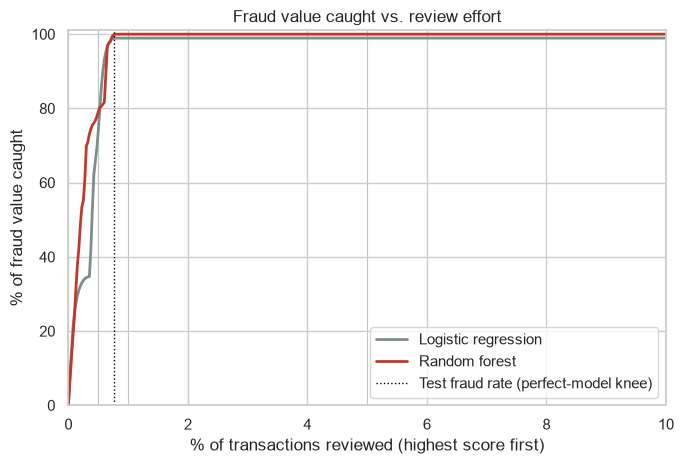

In [15]:
def capture_curve(y, p, amount, max_share=0.10, n=400):
    order = np.argsort(-p, kind="stable")
    caught = np.cumsum(np.asarray(amount)[order] * np.asarray(y)[order])
    share = np.linspace(1 / len(y), max_share, n)
    idx = (share * len(y)).astype(int) - 1
    return share, caught[idx] / caught[-1]

fig, ax = plt.subplots(figsize=(7, 4.8))
for name, p, c in [("Logistic regression", p_lr, "#7f8c8d"), ("Random forest", p_rf, "#c0392b")]:
    x, yv = capture_curve(y_test, p, X_test.amount)
    ax.plot(x * 100, yv * 100, label=name, color=c, lw=2)
ax.axvline(y_test.mean() * 100, ls=":", color="black", lw=1, label="Test fraud rate (perfect-model knee)")
for b in [0.5, 1, 2, 5]:
    ax.axvline(b, color="#bdc3c7", lw=0.8, zorder=0)
ax.set(xlabel="% of transactions reviewed (highest score first)", ylabel="% of fraud value caught",
       title="Fraud value caught vs. review effort", xlim=(0, 10), ylim=(0, 101))
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "04_fraud_value_vs_review.png", dpi=150); plt.show()

### Chosen operating point
Set `CHOSEN_BUDGET` to what the team can actually review. The threshold is the score of the last transaction inside that budget, and that becomes the alert rule in production.

Review top 1.0% -> alert when RF score >= 0.011 (5,526 alerts)


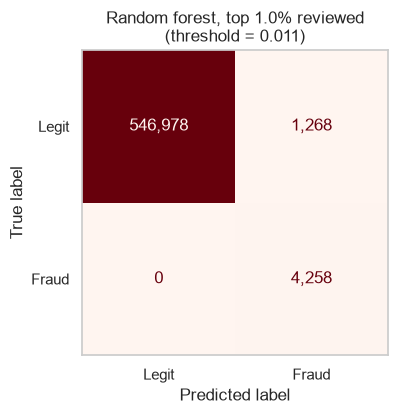

              precision    recall  f1-score   support

       legit      1.000     0.998     0.999    548246
       fraud      0.771     1.000     0.870      4258

    accuracy                          0.998    552504
   macro avg      0.885     0.999     0.935    552504
weighted avg      0.998     0.998     0.998    552504



In [16]:
CHOSEN_BUDGET = 0.01
k = int(np.ceil(CHOSEN_BUDGET * len(p_rf)))
threshold = np.sort(p_rf)[::-1][k - 1]
y_pred = (p_rf >= threshold).astype(int)
print(f"Review top {CHOSEN_BUDGET:.1%} -> alert when RF score >= {threshold:.3f} "
      f"({y_pred.sum():,} alerts)")

fig, ax = plt.subplots(figsize=(5, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Legit", "Fraud"]).plot(
    ax=ax, cmap="Reds", values_format=",", colorbar=False)
ax.grid(False)
ax.set_title(f"Random forest, top {CHOSEN_BUDGET:.1%} reviewed\n(threshold = {threshold:.3f})")
plt.tight_layout(); plt.savefig(FIG / "05_confusion_matrix.png", dpi=150); plt.show()
print(classification_report(y_test, y_pred, target_names=["legit", "fraud"], digits=3))

## 9. Explain the model
Impurity-based importance is fast but biased toward high-cardinality continuous features. We also compute **permutation importance** on the test set: how much does average precision drop when a feature is shuffled? We use all test fraud plus a sample of legitimate rows to keep it quick.

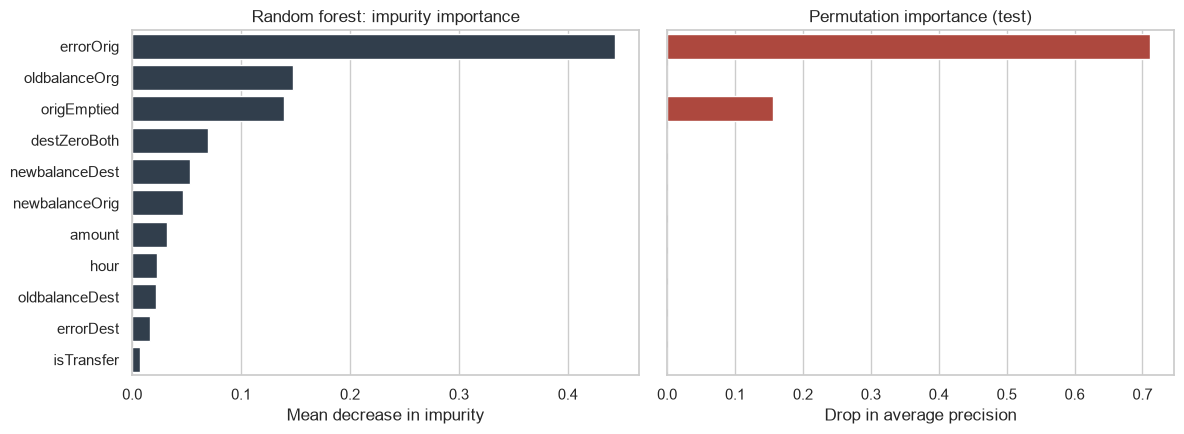

,impurity,permutation_AP_drop
errorOrig,0.4433,0.7109
oldbalanceOrg,0.1475,0.0000
origEmptied,0.1391,0.1566
destZeroBoth,0.0700,0.0001
newbalanceDest,0.0534,0.0000
newbalanceOrig,0.0466,0.0002
amount,0.0315,0.0000
hour,0.0230,0.0000
oldbalanceDest,0.0223,0.0000
errorDest,0.0161,0.0000


In [17]:
imp = pd.DataFrame({"impurity": rf.feature_importances_}, index=FEATURES)
legit_idx = y_test[y_test == 0].sample(min(50_000, (y_test == 0).sum()), random_state=RANDOM_STATE).index
sub = X_test.loc[y_test[y_test == 1].index.union(legit_idx)]
perm = permutation_importance(rf, sub, y_test.loc[sub.index], scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp["permutation_AP_drop"] = perm.importances_mean
imp = imp.sort_values("impurity", ascending=False)
imp.to_csv(RES / "feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
sns.barplot(x=imp.impurity, y=imp.index, ax=axes[0], color="#2c3e50")
axes[0].set(title="Random forest: impurity importance", xlabel="Mean decrease in impurity", ylabel="")
sns.barplot(x=imp.permutation_AP_drop, y=imp.index, ax=axes[1], color="#c0392b")
axes[1].set(title="Permutation importance (test)", xlabel="Drop in average precision")
plt.tight_layout(); plt.savefig(FIG / "06_feature_importance.png", dpi=150); plt.show()
imp

## 10. Sanity check: is it too good?
An average precision near 1.0 should make you suspicious. In PaySim, a fraudulent transfer almost always **empties the account exactly**: `amount == oldbalanceOrg` and `newbalanceOrig == 0`, so `errorOrig == 0`. That is a simulation artifact. Real ledgers are messier.

To test how much depends on this, we retrain the same random forest using only information known **before the transaction posts**: amount, the opening balances, hour and type. No post-transaction balances and no error features. This is a more honest estimate of what the model would do on real data.

In [18]:
PRE_TXN = ["amount", "oldbalanceOrg", "oldbalanceDest", "hour", "isTransfer"]
rf_pre = RandomForestClassifier(n_estimators=200, class_weight="balanced", min_samples_leaf=5,
                                n_jobs=-1, random_state=RANDOM_STATE)
rf_pre.fit(train[PRE_TXN], y_train)
p_pre = rf_pre.predict_proba(test[PRE_TXN])[:, 1]
tbl_pre = review_table(y_test, p_pre, X_test.amount)
tbl_pre.to_csv(RES / "review_budget_table_pre_txn.csv", index=False)
print(f"Pre-transaction-only random forest AP: {average_precision_score(y_test, p_pre):.4f}")
tbl_pre.style.format({"n_reviewed": "{:,}", "score_threshold": "{:.3f}", "fraud_amount_caught": "{:,.0f}",
                      "recall_count": "{:.1%}", "recall_amount": "{:.1%}", "precision": "{:.1%}"})

Pre-transaction-only random forest AP: 0.9083


,review_top,n_reviewed,score_threshold,fraud_caught,recall_count,fraud_amount_caught,recall_amount,precision
0,0.5%,"2,763",0.953,2721,63.9%,"6,363,444,319",94.9%,98.5%
1,1.0%,"5,526",0.310,3752,88.1%,"6,633,540,177",99.0%,67.9%
2,2.0%,"11,051",0.079,4029,94.6%,"6,676,688,078",99.6%,36.5%
3,5.0%,"27,626",0.013,4217,99.0%,"6,699,426,011",100.0%,15.3%


## Summary

Print the numbers to copy into the README and your resume bullet:

In [19]:
r = tbl.set_index("review_top")
print(f"Data: {DATA_PATH.name} | test = steps {test.step.min()}-{test.step.max()} "
      f"({len(test):,} TRANSFER/CASH_OUT txns, {y_test.sum():,} fraud)")
print(f"Average precision: logistic regression {average_precision_score(y_test, p_lr):.3f} | "
      f"random forest {average_precision_score(y_test, p_rf):.3f}")
for b in r.index:
    print(f"Review top {b:>4}: catch {r.loc[b, 'recall_amount']:.1%} of fraud value, "
          f"{r.loc[b, 'recall_count']:.1%} of fraud cases, precision {r.loc[b, 'precision']:.1%}")
print("Top 3 features (permutation):", ", ".join(imp.permutation_AP_drop.nlargest(3).index))
rp = tbl_pre.set_index("review_top")
print()
print(f"Sanity check, pre-transaction features only: AP {average_precision_score(y_test, p_pre):.3f}")
for b in rp.index:
    print(f"Review top {b:>4}: catch {rp.loc[b, 'recall_amount']:.1%} of fraud value, "
          f"{rp.loc[b, 'recall_count']:.1%} of fraud cases, precision {rp.loc[b, 'precision']:.1%}")

Data: PS_20174392719_1491204439457_log.csv | test = steps 355-743 (552,504 TRANSFER/CASH_OUT txns, 4,258 fraud)
Average precision: logistic regression 0.984 | random forest 1.000
Review top 0.5%: catch 79.1% of fraud value, 64.9% of fraud cases, precision 100.0%
Review top 1.0%: catch 100.0% of fraud value, 100.0% of fraud cases, precision 77.1%
Review top 2.0%: catch 100.0% of fraud value, 100.0% of fraud cases, precision 38.5%
Review top 5.0%: catch 100.0% of fraud value, 100.0% of fraud cases, precision 15.4%
Top 3 features (permutation): errorOrig, origEmptied, newbalanceOrig

Sanity check, pre-transaction features only: AP 0.908
Review top 0.5%: catch 94.9% of fraud value, 63.9% of fraud cases, precision 98.5%
Review top 1.0%: catch 99.0% of fraud value, 88.1% of fraud cases, precision 67.9%
Review top 2.0%: catch 99.6% of fraud value, 94.6% of fraud cases, precision 36.5%
Review top 5.0%: catch 100.0% of fraud value, 99.0% of fraud cases, precision 15.3%


**Caveats**
- PaySim is **simulated**. The near-perfect score comes from `errorOrig`, a simulation artifact (fraud empties the account exactly). Section 10 shows the more realistic pre-transaction-only result. Expect real-world performance closer to that, or below it.
- The test set is the last ~20% of rows by time. A production system would retrain regularly and watch for drift.
- Thresholds should be revisited when analyst capacity, fraud mix or the cost per false alert changes.